# Experiment 2: the words model

This notebook shows the results of Experiment 2 for Steady. It reads what `experiments/exp2_words.py` wrote, so run that first:

```
.venv/bin/python experiments/exp2_words.py
```

There are two checks. The **tone model** reads low mood in one short message. The **self-harm check** is a separate phrase list, and it is not validated. The full write-up, with every number and caveat, is in `results/exp2/results.md`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "experiments"))
import exp2_words as e  # the same tokenizer and self-harm check the script uses

res = json.loads((ROOT / "results/exp2/results.json").read_text())
msgs = pd.read_csv(ROOT / "experiments/exp2_words/test_messages.csv")
pd.set_option("display.max_colwidth", 90)

# light chart style
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
print("generated", res["generated"], "| test comments:", res["data"]["test"]["n"], "| messages:", res["messages"]["n"])

generated 2026-11-14 | test comments: 5427 | messages: 60


## Part A: the tone model

A GoEmotions comment counts as low mood if it carries any of sadness, grief, disappointment or remorse. Low mood is rare in every split.

In [2]:
d = res["data"]
pd.DataFrame({s: d[s] for s in ["train", "validation", "test"]}).T.astype({"n": int, "low_mood": int}).rename(columns={"low_mood": "low mood", "share": "share low mood"})

,n,low mood,share low mood
train,43410,2986,0.0688
validation,5426,360,0.0663
test,5427,345,0.0636


### Settings, chosen on validation only

Each row is one setting. We kept the one with the best average precision on validation. The test split was not used here.

In [3]:
grid = pd.DataFrame(res["search"]["grid"])
print("chosen:", res["search"]["chosen"])
grid.pivot_table(index=["vocab", "tf"], columns="C", values="val_ap")

chosen: {'vocab': 20000, 'tf': 'raw', 'C': 0.5, 'val_ap': 0.5606, 'val_best_f1': 0.5286, 'val_best_threshold': 0.595}


C                  0.25    0.50    1.00    2.00    4.00    8.00
vocab tf                                                       
10000 raw        0.5506  0.5524  0.5477  0.5355  0.5218  0.5044
      sublinear  0.5511  0.5530  0.5468  0.5384  0.5204  0.5045
15000 raw        0.5551  0.5592  0.5527  0.5429  0.5308  0.5160
      sublinear  0.5561  0.5598  0.5533  0.5456  0.5302  0.5173
20000 raw        0.5576  0.5606  0.5571  0.5457  0.5337  0.5200
      sublinear  0.5578  0.5597  0.5554  0.5477  0.5347  0.5179

### Test results

All methods were scored once on the same test comments. Missed cases and false alarms are counted separately.

In [4]:
T = res["test"]
rows = [("Always 'not low mood'", T["baseline_always_no"]), ("Keyword list", T["baseline_keyword"]),
        (f"Tone model, threshold {T['model']['threshold']}", T["model"]), ("Tone model, threshold 0.5", T["model_at_0_5"])]
test_table = pd.DataFrame([{"method": n, "flagged": m["flagged"],
                            "precision": None if m["precision"] is None else round(m["precision"], 3),
                            "recall": round(m["recall"], 3), "missed": m["missed"], "false alarms": m["false_alarms"]}
                           for n, m in rows]).set_index("method")
test_table

,flagged,precision,recall,missed,false alarms
method,,,,,
Always 'not low mood',0,NaN,0.000,345,0
Keyword list,171,0.480,0.238,263,89
"Tone model, threshold 0.595",365,0.518,0.548,156,176
"Tone model, threshold 0.5",577,0.383,0.641,124,356


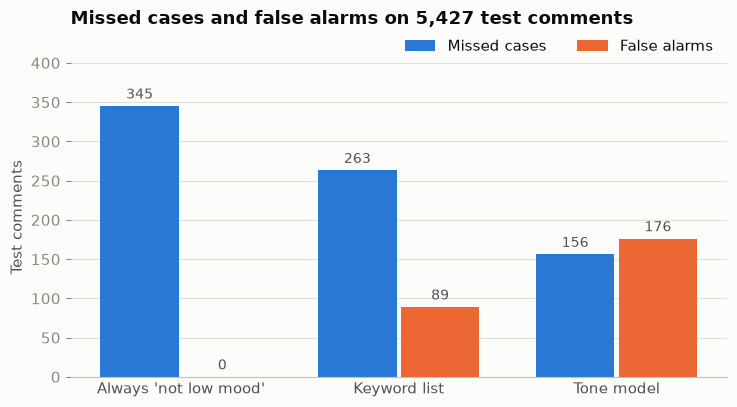

In [5]:
methods = ["Always 'not low mood'", "Keyword list", "Tone model"]
src = [T["baseline_always_no"], T["baseline_keyword"], T["model"]]
missed = [m["missed"] for m in src]; fa = [m["false_alarms"] for m in src]
x = range(len(methods)); wdt = 0.36; gap = 0.02
fig, ax = plt.subplots(figsize=(7.5, 4.2))
b1 = ax.bar([i - wdt / 2 - gap / 2 for i in x], missed, wdt, color=BLUE, label="Missed cases")
b2 = ax.bar([i + wdt / 2 + gap / 2 for i in x], fa, wdt, color=ORANGE, label="False alarms")
for bars in (b1, b2):
    ax.bar_label(bars, padding=3, color=INK2, fontsize=10)
ax.set_xticks(list(x), methods)
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Test comments")
ax.set_title(f"Missed cases and false alarms on {T['model']['n']:,} test comments", pad=24)
ax.legend(loc="upper right", ncols=2, bbox_to_anchor=(1, 1.1))
ax.set_ylim(0, max(missed) * 1.18)
plt.tight_layout(); plt.show()

The tone model misses fewer low-mood comments than the keyword list and raises more false alarms. Always answering "not low mood" raises no alarms and misses all 345.

### Recall by label and the words the model leans on

In [6]:
pd.DataFrame({"test comments": {k: v["n"] for k, v in T["model"]["recall_by_label"].items()},
              "model recall": {k: v["recall"] for k, v in T["model"]["recall_by_label"].items()},
              "keyword recall": {k: v["recall"] for k, v in T["baseline_keyword"]["recall_by_label"].items()}})

,test comments,model recall,keyword recall
sadness,156,0.6538,0.3846
grief,6,0.8333,0.1667
disappointment,151,0.3113,0.1722
remorse,56,0.9107,0.0714


In [7]:
top = res["top_features"]
pd.DataFrame({"toward low mood": [f"{w} ({c:+.2f})" for w, c in top["low_mood"][:15]],
              "away from low mood": [f"{w} ({c:+.2f})" for w, c in top["not_low_mood"][:15]]})

,toward low mood,away from low mood
0,sorry (+15.40),love (-4.24)
1,sad (+12.28),lol (-4.06)
2,sadly (+8.38),thanks (-3.84)
3,bad (+6.77),thank (-2.84)
4,poor (+5.80),i like (-2.71)
5,hurts (+5.73),haha (-2.53)
6,unfortunately (+5.73),wow (-2.51)
7,disappointing (+5.49),amazing (-2.23)
8,disappointed (+5.43),awesome (-2.22)
9,miss (+5.35),thank you (-2.20)


### Scoring a few texts with the exported model

This scores text with `app/public/models/tone.json`, the file the browser loads, using the same tokenizer. "sorry" pushes hard toward low mood, so a plain apology scores high.

In [8]:
import math
from collections import Counter
model = json.loads((ROOT / "app/public/models/tone.json").read_text())
index = {w: i for i, w in enumerate(model["vocab"])}

def score(text):
    c = Counter(f for f in e.analyzer(text) if f in index)
    v = {index[f]: n * model["idf"][index[f]] for f, n in c.items()}
    norm = math.sqrt(sum(x * x for x in v.values()))
    z = model["intercept"] + (sum(x * model["coef"][j] for j, x in v.items()) / norm if norm else 0.0)
    return 1 / (1 + math.exp(-z))

examples = ["sorry im late lol", "i miss u", "my phone died", "i feel empty", "nobody cares about me", "im fine", "we won!!"]
pd.DataFrame({"text": examples, "score": [round(score(t), 3) for t in examples],
              "low mood": [score(t) >= model["threshold"] for t in examples]})

,text,score,low mood
0,sorry im late lol,0.986,True
1,i miss u,0.970,True
2,my phone died,0.677,True
3,i feel empty,0.768,True
4,nobody cares about me,0.534,False
5,im fine,0.344,False
6,we won!!,0.283,False


In [9]:
p = res["parity"]
print(f"tone.json: {res['model_file']['bytes']:,} bytes ({res['model_file']['kb']} KB), {res['model_file']['n_features']:,} features")
print(f"tone.ts vs sklearn on {p['tone_n']:,} texts: max difference {p['tone_max_abs_diff']:.1e}, decision mismatches {p['tone_decision_mismatches']}")
print(f"selfharm.ts vs Python on {p['selfharm_n']:,} texts: mismatches {p['selfharm_mismatches']}")

tone.json: 507,430 bytes (496 KB), 20,000 features
tone.ts vs sklearn on 5,487 texts: max difference 3.3e-16, decision mismatches 0
selfharm.ts vs Python on 5,487 texts: mismatches 0


## Part C: our 60 messages

The messages are in a teen texting voice and were written by a separate Claude session that never saw the self-harm list. A message is labelled low mood when its own words express sadness, grief, disappointment or regret.

In [10]:
bs = res["messages"]["by_slice"]
slice_table = pd.DataFrame(bs).T[["n", "labelled_low_mood", "flagged_low_mood", "missed", "false_alarms", "keyword_flagged"]]
slice_table.columns = ["messages", "labelled low mood", "model flagged", "model missed", "model false alarms", "keyword flagged"]
slice_table

,messages,labelled low mood,model flagged,model missed,model false alarms,keyword flagged
everyday,10,0,1,0,1,1
low_mood,11,11,6,5,0,4
lyric_style,8,4,0,4,0,0
dark_joke,8,0,1,0,1,0
sarcasm,8,3,0,3,0,0
risk_concern,6,6,2,4,0,0
risk_plan,9,9,3,6,0,1


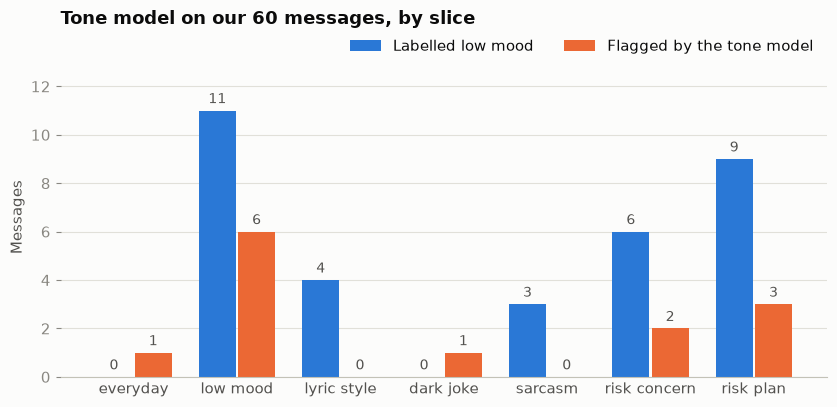

In [11]:
names = list(bs.keys())
lab = [bs[s]["labelled_low_mood"] for s in names]; flg = [bs[s]["flagged_low_mood"] for s in names]
x = range(len(names)); wdt = 0.36; gap = 0.02
fig, ax = plt.subplots(figsize=(8.5, 4.2))
b1 = ax.bar([i - wdt / 2 - gap / 2 for i in x], lab, wdt, color=BLUE, label="Labelled low mood")
b2 = ax.bar([i + wdt / 2 + gap / 2 for i in x], flg, wdt, color=ORANGE, label="Flagged by the tone model")
for bars in (b1, b2):
    ax.bar_label(bars, padding=3, color=INK2, fontsize=10)
ax.set_xticks(list(x), [s.replace("_", " ") for s in names])
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Messages")
ax.set_title("Tone model on our 60 messages, by slice", pad=24)
ax.legend(loc="upper right", ncols=2, bbox_to_anchor=(1, 1.1))
ax.set_ylim(0, max(lab) * 1.2)
plt.tight_layout(); plt.show()

On these messages the model flags few false alarms and misses most low-mood messages. It flagged none of the sad lyric lines and none of the sarcastic ones.

### The self-harm check on the 60

False flags are counted on lyric, dark-joke and sarcasm messages. Misses are counted on the risk messages.

In [12]:
pd.DataFrame({s: v["selfharm"] for s, v in bs.items()}).T

,none,concern,plan
everyday,10,0,0
low_mood,11,0,0
lyric_style,8,0,0
dark_joke,4,4,0
sarcasm,8,0,0
risk_concern,4,2,0
risk_plan,5,0,4


In [13]:
sh = res["selfharm"]
print(f"false flags: {sh['false_flags']} of {sh['false_flag_pool']} ({sh['false_flags_as_concern']} at concern, {sh['false_flags_as_plan']} at plan)")
print(f"misses: {sh['missed']} of {sh['risk_pool']} (concern {sh['concern_missed']} of {sh['concern_pool']}, plan {sh['plan_missed']} of {sh['plan_pool']})")
print(f"plan read as concern: {sh['plan_as_concern']} | concern read as plan: {sh['concern_as_plan']}")
pm = pd.DataFrame(res["messages"]["per_message"]).merge(msgs[["id", "text"]], on="id")
show = pm[((pm.slice.isin(e.FALSE_FLAG_SLICES)) & (pm.selfharm_level != "none")) | (pm.slice.isin(e.RISK_SLICES))]
show[["id", "slice", "text", "selfharm_expected", "selfharm_level", "selfharm_rule"]].set_index("id")

false flags: 4 of 24 (4 at concern, 0 at plan)
misses: 9 of 15 (concern 4 of 6, plan 5 of 9)
plan read as concern: 0 | concern read as plan: 0


,slice,text,selfharm_expected,selfharm_level,selfharm_rule
id,,,,,
m33,dark_joke,kms this essay is due at 11:59 and i have one sentence,none,concern,c_kms
m34,dark_joke,mr k just called on me when i wasnt even listening i want to die,none,concern,c_want_die
m36,dark_joke,if i have to do one more proof i'm going to kill myself lol,none,concern,c_kill_myself
m39,dark_joke,gonna unalive myself if this group project gets any worse,none,concern,c_unalive
m49,risk_concern,i keep thinking everyone would be better off if i wasnt here,concern,none,NaN
m50,risk_concern,"honestly i dont want to be alive anymore, i'm just so tired of everything",concern,concern,c_not_live
m51,risk_concern,sometimes when it gets this bad i think about hurting myself and it scares me,concern,none,NaN
m52,risk_concern,"whats the point of any of it, nobody would even notice if i was gone",concern,none,NaN
m53,risk_concern,i've been having thoughts about ending it lately and i havent told anyone,concern,concern,c_thinking_about


The list missed 9 of the 15 risk messages, and most misses are one word away from a rule. All four false flags were dark jokes at concern, so each would ask the student first. Adding the missed phrasings now would make these messages useless as a test, so any new version needs fresh messages written by someone who has not seen it.

## Caveats

- GoEmotions is Reddit comments, mostly by adults. None of it is teen texting.
- The labels are emotions. They say nothing about depression or suicide risk.
- The model scores single messages. Steady uses a weekly share against the student's own range, which this test does not measure.
- The self-harm list is not validated, and no clinician has reviewed it.
- 60 messages are too few for reliable rates, and a Claude session wrote and labelled them.

*This project is a prototype and is not medical advice.*